# AutoPredict AI · Análise e avaliação dos modelos

**Random Forest · Isolation Forest · MATLAB/Simulink**

Este documento avalia os modelos treinados no AI4I 2020 e sua resposta a dois cenários de telemetria simulada. Pandas e NumPy organizam os dados; Seaborn e Matplotlib representam as distribuições, as previsões e a matriz de confusão.

**Sequência da análise:** identificar os artefatos → reconstruir treino/teste → executar inferência nos MAT → interpretar os gráficos → verificar os arquivos gerados.

O notebook não treina modelos nem ajusta limiares. **Classificação de falha RF**, **anomalia IF** e **sensor fora da faixa de treinamento** são resultados distintos. A perturbação térmica é sintética e não confirma uma falha física.

## 1. Ambiente e localização do projeto

Selecione o interpretador `.venv/bin/python` no VS Code e execute **Run All / Executar Tudo**. A raiz é procurada no diretório atual e em seus ancestrais; também é verificada a pasta `~/autopredict-ai`. Se o kernel iniciar em uma pasta sem relação com o repositório, defina a variável de ambiente `AUTOPREDICT_ROOT` com o caminho da sua cópia antes de iniciar o kernel.

As explicações ficam nas células Markdown; as células de código realizam cada operação sem chamar `main.py`, `train_models` ou métodos `fit`.

In [1]:
from pathlib import Path
import os
import sys


def find_project_root():
    configured = os.environ.get("AUTOPREDICT_ROOT")
    starts = [Path(configured).expanduser()] if configured else [Path.cwd(), Path.home() / "autopredict-ai"]
    for start in starts:
        for candidate in (start.resolve(), *start.resolve().parents):
            if (candidate / "src/predict.py").is_file() and (candidate / "data/processed/ai4i2020_processed.csv").is_file():
                return candidate
    raise FileNotFoundError("Raiz não encontrada. Abra o projeto ou configure AUTOPREDICT_ROOT antes de iniciar o kernel.")


ROOT = find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
FIGURES = ROOT / "reports/figures"
FIGURES.mkdir(parents=True, exist_ok=True)
print(f"Projeto: {ROOT.name}")
print(f"Figuras: {FIGURES.relative_to(ROOT)}")
print(f"Python: {sys.version.split()[0]}")

Projeto: autopredict-ai
Figuras: reports/figures
Python: 3.14.4


In [2]:
import hashlib
import importlib.metadata
import json
import re
import tempfile

import h5py
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, MaxNLocator
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image as PILImage
from IPython.display import Markdown, display, Image as NotebookImage
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score

from src.features import create_features
from src.model_store import load_models, MODEL_FILENAMES
from src.predict import predict_batch
from src.simulink_bridge import read_simulink_mat, load_training_sensor_ranges
from src.validation import SENSOR_COLUMNS, FEATURE_COLUMNS, read_csv_checked, split_training_rows

sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans", rc={
    "figure.facecolor": "white", "axes.facecolor": "white",
    "figure.dpi": 150, "savefig.dpi": 300,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.linewidth": 0.6,
    "grid.alpha": 0.18, "grid.linewidth": 0.5,
    "axes.labelcolor": "#243247", "text.color": "#243247",
    "xtick.color": "#475569", "ytick.color": "#475569",
    "font.size": 8, "axes.labelsize": 8, "axes.titlesize": 9,
    "xtick.labelsize": 7, "ytick.labelsize": 7,
})
COLORS = {"Treinamento": "#64748B", "Normal": "#2563EB", "Perturbado": "#D97706"}
INK, GRAY, RED = "#243247", "#64748B", "#B91C1C"
EXPECTED_FIGURES = ["temperature_comparison.png", "confusion_matrix.png",
                    "model_predictions.png", "sensor_distributions.png"]
VERTICAL_FIGURES = set(EXPECTED_FIGURES) - {"sensor_distributions.png"}
staging_context = tempfile.TemporaryDirectory(prefix=".figures-", dir=FIGURES)
STAGING = Path(staging_context.name)


def format_br(value, decimals=0):
    return f"{value:,.{decimals}f}".replace(",", "_").replace(".", ",").replace("_", ".")


def format_axis(ax, x_decimals=0, y_decimals=0):
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, position: format_br(value, x_decimals)))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, position: format_br(value, y_decimals)))


def analysis_figure(title, subtitle):
    fig = plt.figure(figsize=(3.6, 4.5), facecolor="white")
    fig.text(0.09, 0.918, title, fontsize=14, fontweight="bold", va="top", linespacing=1.1)
    fig.text(0.09, 0.802, subtitle, fontsize=7.2, color=GRAY, va="top", linespacing=1.35)
    return fig


def save_figure(fig, filename):
    if filename not in EXPECTED_FIGURES:
        raise ValueError(f"Nome de figura não previsto: {filename}")
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    width, height = fig.canvas.get_width_height()
    text_boxes = [text.get_window_extent(renderer) for text in fig.texts if text.get_text().strip()]
    for box in text_boxes:
        assert box.x0 >= 0 and box.y0 >= 0 and box.x1 <= width and box.y1 <= height, filename
    for index, box in enumerate(text_boxes):
        assert not any(box.overlaps(other) for other in text_boxes[index + 1:]), filename
    path = STAGING / filename
    fig.savefig(path, dpi=300, bbox_inches=None, facecolor="white")
    plt.close(fig)
    with PILImage.open(path) as image:
        image.verify()
    with PILImage.open(path) as image:
        assert min(image.info.get("dpi", (0, 0))) >= 299.9
        if filename in VERTICAL_FIGURES:
            assert image.size == (1080, 1350), (filename, image.size)
    print(f"Figura gerada e verificada: {filename}")
    display(NotebookImage(filename=str(path), width=1080))


versions = pd.Series({package: importlib.metadata.version(package) for package in
    ["numpy", "pandas", "scikit-learn", "matplotlib", "seaborn", "h5py"]}, name="Versão")
display(versions.to_frame())

,Versão
numpy,2.5.3
pandas,3.0.6
scikit-learn,1.9.1
matplotlib,3.11.2
seaborn,0.13.2
h5py,3.16.0


## 2. Rastreabilidade e preservação dos artefatos

O carregamento utiliza `load_models`, respeitando `models/current.json` quando existe e mantendo o suporte aos arquivos legados. A tabela registra os hashes dos modelos selecionados e das entradas principais; uma verificação ao final confirma que os arquivos preexistentes de código, configuração, dados e modelos permaneceram iguais.

Os hashes identificam os arquivos avaliados. Eles não substituem uma validação física dos sensores nem acrescentam informações de treinamento que não estejam registradas nos artefatos.

In [3]:
DATA_PATH = ROOT / "data/processed/ai4i2020_processed.csv"
SCENARIOS = {
    "Normal": ROOT / "telemetry_normal_torque_teste.mat",
    "Perturbado": ROOT / "telemetry_fault_corrigido.mat",
}
manifest = ROOT / "models/current.json"
generation = json.loads(manifest.read_text())["generation"] if manifest.exists() else None
model_directory = ROOT / "models/versions" / generation if generation else ROOT / "models"

protected = {ROOT / "main.py", ROOT / "requirements.txt", ROOT / ".gitignore"}
if (ROOT / "README.md").exists():
    protected.add(ROOT / "README.md")
for directory in ["src", "tests", "data", "models", "telemetry_backcup"]:
    protected.update(path for path in (ROOT / directory).rglob("*")
                     if path.is_file() and "__pycache__" not in path.parts)
protected.update(ROOT.glob("*.mat"))


def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


original_hashes = {path: sha256(path) for path in sorted(protected)}
selected_paths = [DATA_PATH, *SCENARIOS.values(), *(model_directory / name for name in MODEL_FILENAMES)]
display(pd.DataFrame({"Arquivo": [str(path.relative_to(ROOT)) for path in selected_paths],
                      "SHA-256": [sha256(path) for path in selected_paths]}))
print(f"Versão selecionada: {generation or 'arquivos legados'}")
classifier, detector = load_models(ROOT / "models")

,Arquivo,SHA-256
0,data/processed/ai4i2020_processed.csv,a617b5f26481a946e044aa6584252f68567bb8d5d05733...
1,telemetry_normal_torque_teste.mat,341cae3a168d113e5a894eca0ea05e7b7b9a428aad09fa...
2,telemetry_fault_corrigido.mat,bc33903123c4ea12a960817fea300a2716d0bd703e7aaf...
3,models/versions/23f256890ef443b1bc041fdc7c52e8...,bae59d9f90c87e5b47f3a85d3de80993e651fc300cb143...
4,models/versions/23f256890ef443b1bc041fdc7c52e8...,be271bedda12f30538a9d1ad53ee3ec2d4e3cb851d6947...


Versão selecionada: 23f256890ef443b1bc041fdc7c52e890


## 3. Reconstrução dos conjuntos de treinamento e teste

`split_training_rows` reutiliza a divisão do projeto: **80% / 20%, estratificada por `machine_failure`, `random_state=42`**. O conjunto de teste é utilizado apenas na avaliação. As faixas e distribuições de referência são calculadas exclusivamente com o treinamento.

`create_features` recalcula os nove atributos para verificar a consistência com o CSV processado, preservando as fórmulas existentes. `power_estimate` é torque × RPM, não potência em watts.

In [4]:
processed = read_csv_checked(DATA_PATH)
training, testing = split_training_rows(processed)
recalculated = create_features(processed[SENSOR_COLUMNS])[FEATURE_COLUMNS]
np.testing.assert_allclose(processed[FEATURE_COLUMNS], recalculated, rtol=1e-10, atol=1e-8)
assert set(training.index).isdisjoint(testing.index)

training_ranges = load_training_sensor_ranges(DATA_PATH)
for sensor, bounds in training_ranges.items():
    np.testing.assert_allclose(bounds, [training[sensor].min(), training[sensor].max()])

split_summary = pd.DataFrame([
    {"Conjunto": label, "Registros": len(frame), "Sem falha": int((frame.machine_failure == 0).sum()),
     "Com falha": int((frame.machine_failure == 1).sum())}
    for label, frame in [("Treinamento", training), ("Teste", testing)]
]).set_index("Conjunto")
display(split_summary)
display(training[SENSOR_COLUMNS].agg(["min", "mean", "max"]).T.rename(
    columns={"min": "Mínimo", "mean": "Média", "max": "Máximo"}).round(3))

,Registros,Sem falha,Com falha
Conjunto,,,
Treinamento,8000,7729,271
Teste,2000,1932,68


,Mínimo,Média,Máximo
rotational_speed_rpm,1168.0,1539.357,2886.0
process_temperature_k,305.7,310.006,313.8
torque_nm,3.8,40.003,76.6
air_temperature_k,295.3,300.005,304.5
tool_wear_min,0.0,107.685,253.0


## 4. Inferência sobre os arquivos MAT finais

A leitura dos cinco sensores é delegada a `read_simulink_mat`. O vetor de tempo, descartado pela função de inferência, é extraído da mesma matriz HDF5 para os gráficos e conferido com os sensores lidos. A unidade de segundos segue a configuração da simulação informada pelo projeto; os MAT numéricos não contêm nomes ou unidades suficientes para validá-la fisicamente.

As previsões vêm de `predict_batch`, sem recalcular a classificação a partir da probabilidade arredondada. O indicador contínuo do IF é obtido do detector existente, com `create_features`, apenas para explicar sua distância do limiar de anomalia.

In [5]:
def evaluate_scenario(path):
    sensors = read_simulink_mat(path)
    with h5py.File(path, "r") as mat:
        matrix = np.asarray(mat["telemetry_data"])
    matrix = matrix.T if matrix.shape[0] == 6 else matrix
    np.testing.assert_array_equal(sensors[SENSOR_COLUMNS], matrix[:, 1:])
    predictions = predict_batch(sensors, ROOT / "models")
    features = create_features(sensors)[FEATURE_COLUMNS]
    np.testing.assert_allclose(predictions.failure_probability,
                               np.round(classifier.predict_proba(features)[:, 1], 4))
    decisions = detector.decision_function(features)
    np.testing.assert_array_equal(predictions.is_anomaly, (decisions < 0).astype(int))
    result = pd.concat([sensors.reset_index(drop=True), predictions.reset_index(drop=True)], axis=1)
    result.insert(0, "time_s", matrix[:, 0])
    result["if_decision"] = decisions
    result["period"] = np.where(result.time_s < 50, "t < 50 s", "t ≥ 50 s")
    result["outside_training"] = pd.DataFrame({
        sensor: (result[sensor] < bounds[0]) | (result[sensor] > bounds[1])
        for sensor, bounds in training_ranges.items()
    }).any(axis=1)
    return result


runs = {name: evaluate_scenario(path) for name, path in SCENARIOS.items()}
records = []
for name, frame in runs.items():
    for period, selected in [("Total", frame), *frame.groupby("period", sort=True)]:
        records.append({
            "Cenário": name, "Período": period, "Amostras": len(selected),
            "Falhas RF": int(selected.failure_predicted.sum()),
            "Anomalias IF": int(selected.is_anomaly.sum()),
            "Sensores fora da faixa (amostras)": int(selected.outside_training.sum()),
            "Probabilidade média (%)": selected.failure_probability.mean() * 100,
            "Probabilidade máxima (%)": selected.failure_probability.max() * 100,
        })
summary = pd.DataFrame(records).set_index(["Cenário", "Período"])
display(summary.round(3))
for name, frame in runs.items():
    matches = (int(frame.failure_predicted.sum()) == 9
               and int(frame.is_anomaly.sum()) == 0
               and int(frame.loc[frame.time_s >= 50, "failure_predicted"].sum()) == 0)
    print(f"{name}: {'coincide' if matches else 'DIVERGE'} da referência histórica (9 classificações RF, 0 IF, 0 classificações RF após 50 s; avisos de faixa são independentes).")

Amostras  Falhas RF  Anomalias IF  \
Cenário    Período                                       
Normal     Total           58          9             0   
           t < 50 s        32          9             0   
           t ≥ 50 s        26          0             0   
Perturbado Total           60          9             0   
           t < 50 s        33          9             0   
           t ≥ 50 s        27          0             0   

                     Sensores fora da faixa (amostras)  \
Cenário    Período                                       
Normal     Total                                     0   
           t < 50 s                                  0   
           t ≥ 50 s                                  0   
Perturbado Total                                    27   
           t < 50 s                                  0   
           t ≥ 50 s                                 27   

                     Probabilidade média (%)  Probabilidade máxima (%)  
Cenário    Período                                                      
Normal     Total                       8.621                      54.0  
           t < 50 s                   15.500                      54.0  
           t ≥ 50 s                    0.154                       2.0  
Perturbado Total                       9.183                      54.0  
           t < 50 s                   15.030                      54.0  
           t ≥ 50 s                    2.037                       3.0

Normal: coincide da referência histórica (9 classificações RF, 0 IF, 0 classificações RF após 50 s; avisos de faixa são independentes).
Perturbado: coincide da referência histórica (9 classificações RF, 0 IF, 0 classificações RF após 50 s; avisos de faixa são independentes).


### Amostras, intervalos e eventos

As contagens representam **registros classificados**, não eventos físicos independentes. O solver gera amostras quase simultâneas no início da simulação e ao redor de 50 s. As médias são por amostra, sem ponderação pelo tempo; os dois arquivos possuem instantes diferentes após a transição.

A simulação começa em aproximadamente 1.300 rpm, sem representar a partida física completa de um motor. As classificações iniciais não são automaticamente falsos positivos. Sem rótulos físicos independentes por amostra, não é possível construir uma matriz de confusão da telemetria.

In [6]:
transition_rows = []
for name, frame in runs.items():
    before = frame[frame.time_s < 50].iloc[-1]
    after = frame[frame.time_s >= 50].iloc[0]
    for side, row in [("Última antes", before), ("Primeira a partir", after)]:
        transition_rows.append({
            "Cenário": name, "Registro": side, "Tempo (s)": row.time_s,
            "Processo (K)": row.process_temperature_k, "Ambiente (K)": row.air_temperature_k,
            "ΔT (K)": row.process_temperature_k - row.air_temperature_k,
            "Probabilidade RF (%)": row.failure_probability * 100,
            "Decisão IF": row.if_decision,
        })
display(pd.DataFrame(transition_rows).set_index(["Cenário", "Registro"]).round(5))
perturbed = runs["Perturbado"]
last_before = perturbed[perturbed.time_s < 50].iloc[-1]
first_after = perturbed[perturbed.time_s >= 50].iloc[0]
observed_jump = first_after.process_temperature_k - last_before.process_temperature_k
print(f"Salto observado na fronteira de 50 s: {observed_jump:g} K.")
print("Os registros imediatamente antes e depois representam uma única perturbação controlada.")

Tempo (s)  Processo (K)  Ambiente (K)  ΔT (K)  \
Cenário    Registro                                                           
Normal     Última antes        48.60378         309.0         300.0     9.0   
           Primeira a partir   50.60378         309.0         300.0     9.0   
Perturbado Última antes        50.00000         309.0         300.0     9.0   
           Primeira a partir   50.00000         324.0         300.0    24.0   

                              Probabilidade RF (%)  Decisão IF  
Cenário    Registro                                             
Normal     Última antes                        0.0     0.14691  
           Primeira a partir                   0.0     0.13783  
Perturbado Última antes                        0.0     0.13584  
           Primeira a partir                   2.0     0.05247

Salto observado na fronteira de 50 s: 15 K.
Os registros imediatamente antes e depois representam uma única perturbação controlada.


## 5. Figura 1 · Temperatura do processo

O gráfico de linhas compara a temperatura de processo dos dois arquivos MAT finais, usando os instantes exportados pelo Simulink. As linhas conectam os registros reais, sem suavização. Azul identifica o cenário normal e laranja o perturbado.

O salto observado aos 50 s é de **15 K**. A faixa cinza mostra o mínimo–máximo do conjunto de treinamento, permitindo reconhecer valores fora do domínio observado. Essa faixa **não é um limite físico de segurança**, e o salto sintético não comprova uma avaria.

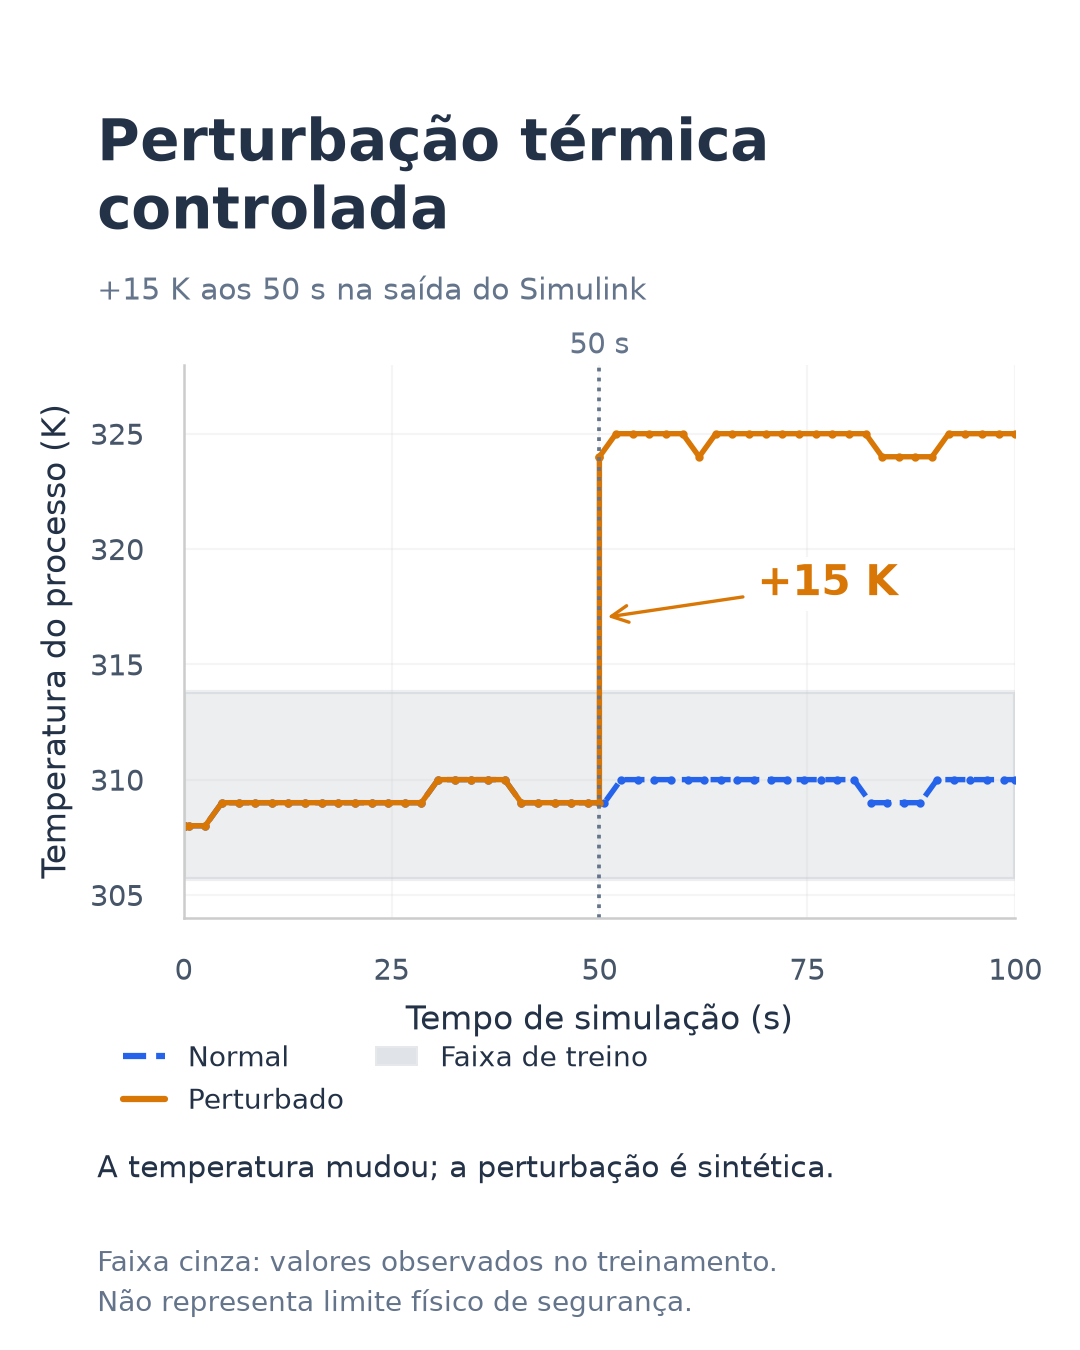

Figura conferida e preservada: temperature_comparison.png


In [7]:
fig = analysis_figure("Perturbação térmica\ncontrolada", "+15 K aos 50 s na saída do Simulink")
ax = fig.add_axes([0.17, 0.32, 0.77, 0.41])
low, high = training_ranges["process_temperature_k"]
ax.axhspan(low, high, color=COLORS["Treinamento"], alpha=0.12, zorder=0)
for name, frame in runs.items():
    ax.plot(frame.time_s, frame.process_temperature_k, color=COLORS[name],
            linestyle="--" if name == "Normal" else "-", marker=".", markersize=2,
            linewidth=1.3, label=name)
ax.axvline(50, color=GRAY, linestyle=":", linewidth=0.9)
ax.text(50, 1.02, "50 s", ha="center", transform=ax.get_xaxis_transform(), color=GRAY, fontsize=7)
ax.annotate(f"+{format_br(observed_jump)} K", xy=(50, 317), xytext=(69, 318),
            color=COLORS["Perturbado"], fontsize=10, fontweight="bold",
            arrowprops={"arrowstyle": "->", "lw": 0.8, "color": COLORS["Perturbado"]},
            bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.5})
ax.set(xlabel="Tempo de simulação (s)", ylabel="Temperatura do processo (K)",
       xlim=(0, 100), ylim=(304, 328), xticks=[0, 25, 50, 75, 100])
ax.yaxis.set_major_locator(MaxNLocator(5))
format_axis(ax)
fig.legend(handles=[Line2D([], [], color=COLORS["Normal"], linestyle="--", label="Normal"),
                    Line2D([], [], color=COLORS["Perturbado"], label="Perturbado"),
                    Patch(facecolor=COLORS["Treinamento"], alpha=0.2, label="Faixa de treino")],
           loc="upper left", bbox_to_anchor=(0.09, 0.245), ncol=2, frameon=False,
           fontsize=6.8, handlelength=1.5, columnspacing=1.1)
fig.text(0.09, 0.128, "A temperatura mudou; a perturbação é sintética.", fontsize=7.1, color=INK)
fig.text(0.09, 0.082, "Faixa cinza: valores observados no treinamento.\nNão representa limite físico de segurança.",
         fontsize=6.8, color=GRAY, va="top", linespacing=1.5)
save_figure(fig, "temperature_comparison.png")

## 6. Figura 2 · Resposta do Random Forest e do Isolation Forest

Os quatro painéis mostram as previsões sobre as mesmas amostras dos dois cenários. O RF é representado pela probabilidade estimada e pelo limiar de 50%; os pontos vermelhos são registros classificados como falha. O IF é representado por `decision_function`, cuja região negativa indica anomalia. Cada par utiliza a mesma escala.

Foram observadas **nove amostras classificadas como falha nos instantes iniciais de cada cenário**, nenhuma anomalia IF e nenhuma nova classificação de falha RF após 50 s. O validador independente registrou 27 avisos de temperatura fora da faixa no cenário perturbado. A queda do indicador IF no cenário perturbado mostra sensibilidade à mudança, mas não uma anomalia detectada. As nove classificações não representam nove eventos físicos independentes.

Figura gerada e verificada: model_predictions.png


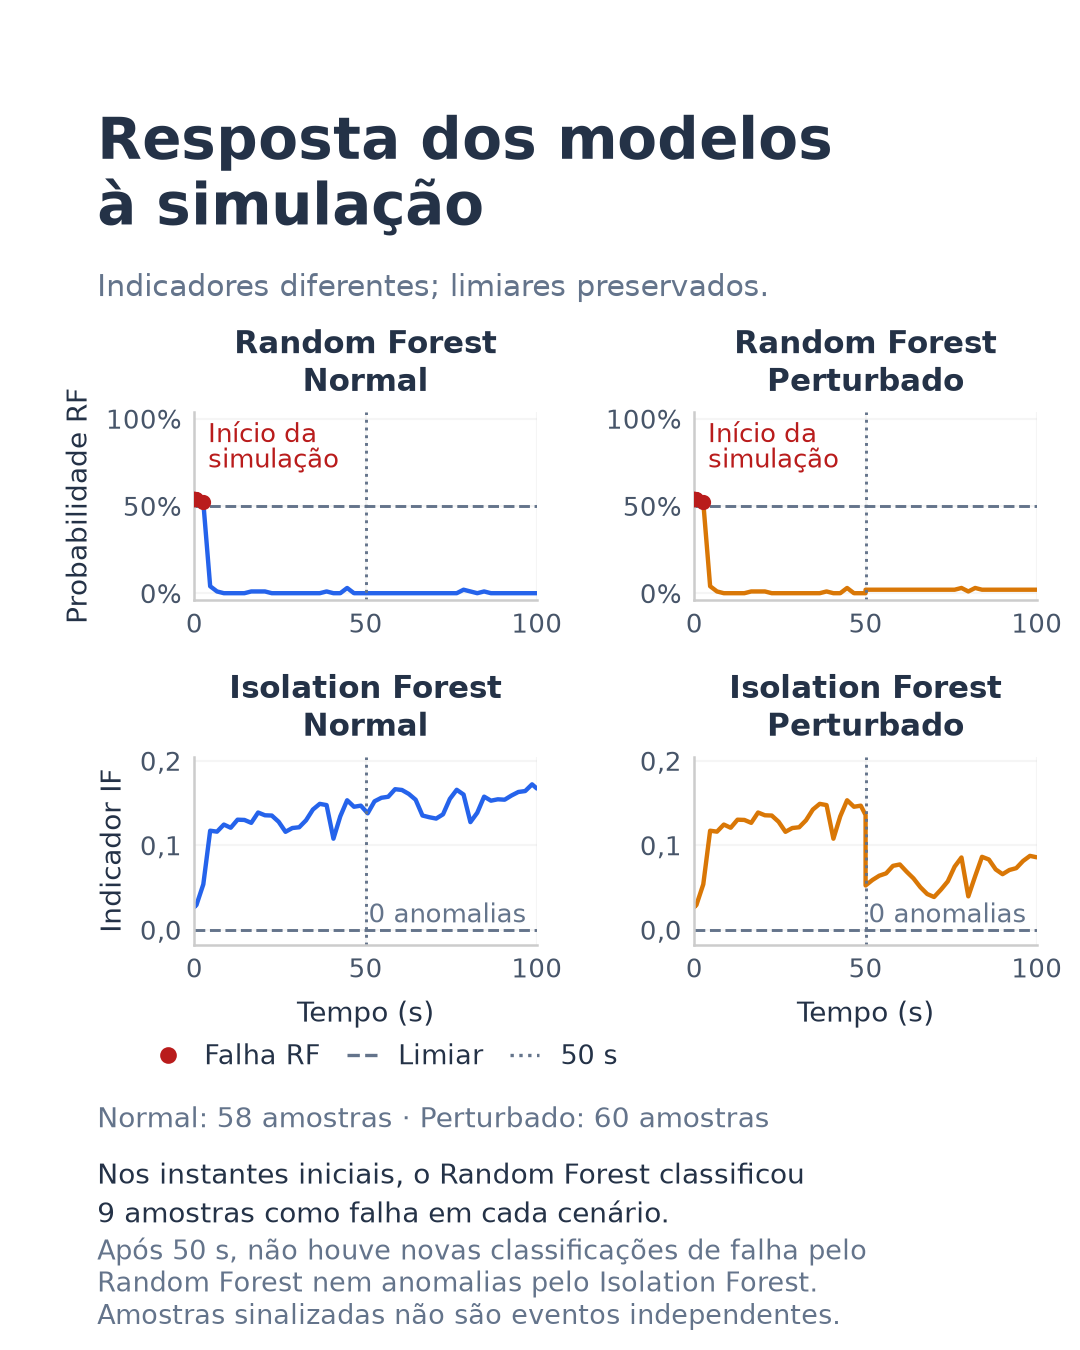

In [8]:
fig = analysis_figure("Resposta dos modelos\nà simulação", "Indicadores diferentes; limiares preservados.")
grid = fig.add_gridspec(2, 2, left=0.18, right=0.96, bottom=0.30, top=0.695,
                        wspace=0.46, hspace=0.83)
axes = np.array([[fig.add_subplot(grid[row, column]) for column in range(2)] for row in range(2)])
for column, (name, frame) in enumerate(runs.items()):
    positive = frame.failure_predicted.astype(bool)
    rf_ax, if_ax = axes[:, column]
    rf_ax.plot(frame.time_s, frame.failure_probability, color=COLORS[name], linewidth=1.05)
    rf_ax.scatter(frame.loc[positive, "time_s"], frame.loc[positive, "failure_probability"],
                  color=RED, s=7, zorder=4)
    rf_ax.axhline(0.5, color=GRAY, linestyle="--", linewidth=0.7)
    rf_ax.set(title=f"Random Forest\n{name}", xlim=(0, 100), ylim=(-0.04, 1.04),
              xticks=[0, 50, 100], yticks=[0, 0.5, 1])
    rf_ax.yaxis.set_major_formatter(FuncFormatter(lambda value, position: f"{format_br(value * 100)}%"))
    rf_ax.xaxis.set_major_formatter(FuncFormatter(lambda value, position: format_br(value)))
    rf_ax.text(0.04, 0.97, "Início da\nsimulação", transform=rf_ax.transAxes, ha="left", va="top",
               fontsize=6.2, color=RED, linespacing=1.1)
    if_ax.plot(frame.time_s, frame.if_decision, color=COLORS[name], linewidth=1.05)
    if_ax.axhline(0, color=GRAY, linestyle="--", linewidth=0.7)
    if_ax.set(title=f"Isolation Forest\n{name}", xlabel="Tempo (s)", xlim=(0, 100),
              ylim=(-0.018, 0.205), xticks=[0, 50, 100], yticks=[0, 0.1, 0.2])
    format_axis(if_ax, y_decimals=1)
    if_ax.text(0.97, 0.12, f"{format_br(frame.is_anomaly.sum())} anomalias", transform=if_ax.transAxes,
                ha="right", fontsize=6.2, color=GRAY)
    for ax in (rf_ax, if_ax):
        ax.axvline(50, color=GRAY, linestyle=":", linewidth=0.7)
        ax.set_title(ax.get_title(), fontsize=7.5, pad=5)
        ax.tick_params(labelsize=6.3, pad=1, length=2)
        ax.xaxis.label.set_size(6.7)
axes[0, 0].set_ylabel("Probabilidade RF", fontsize=6.8, labelpad=3)
axes[1, 0].set_ylabel("Indicador IF", fontsize=6.8, labelpad=3)
fig.legend(handles=[Line2D([], [], marker="o", linestyle="none", color=RED, markersize=3, label="Falha RF"),
                    Line2D([], [], color=GRAY, linestyle="--", linewidth=0.8, label="Limiar"),
                    Line2D([], [], color=GRAY, linestyle=":", linewidth=0.8, label="50 s")],
           loc="upper left", bbox_to_anchor=(0.12, 0.245), ncol=3, frameon=False,
           fontsize=6.4, handlelength=1.1, columnspacing=1)
counts_text = " · ".join(f"{name}: {format_br(len(frame))} amostras" for name, frame in runs.items())
fig.text(0.09, 0.165, counts_text, fontsize=6.7, color=GRAY)
initial_counts = [int(frame.loc[frame.time_s < 50, "failure_predicted"].sum()) for frame in runs.values()]
post_rf = [int(frame.loc[frame.time_s >= 50, "failure_predicted"].sum()) for frame in runs.values()]
post_if = [int(frame.loc[frame.time_s >= 50, "is_anomaly"].sum()) for frame in runs.values()]
initial_message = (
    f"Nos instantes iniciais, o Random Forest classificou\n{initial_counts[0]} amostras como falha em cada cenário."
    if initial_counts[0] == initial_counts[1]
    else f"Nos instantes iniciais, o Random Forest classificou\n{initial_counts[0]} e {initial_counts[1]} amostras como falha, respectivamente."
)
fig.text(0.09, 0.143, initial_message, fontsize=6.7, color=INK, va="top", linespacing=1.3)
post_message = ("Após 50 s, não houve novas classificações de falha pelo\nRandom Forest nem anomalias pelo Isolation Forest." if not any(post_rf + post_if)
                else f"Após 50 s: RF {post_rf[0]}/{post_rf[1]}; IF {post_if[0]}/{post_if[1]}.")
fig.text(0.09, 0.085, post_message + "\nAmostras sinalizadas não são eventos independentes.",
         fontsize=6.5, color=GRAY, va="top", linespacing=1.2)
save_figure(fig, "model_predictions.png")

## 7. Avaliação supervisionada no conjunto de teste AI4I

A avaliação usa os rótulos de `machine_failure` da divisão de teste original, reconstruída pela função do projeto. A inferência reutiliza o pré-processamento existente e aplica o limiar de 0,5 antes do arredondamento. Esta etapa não utiliza rótulos dos cenários Simulink.

Os valores históricos `TN=1923, FP=9, FN=13, TP=55` servem apenas para conferir a reprodução do experimento. A matriz e as métricas são recalculadas com os dados e modelos carregados; eventuais divergências são informadas. ROC-AUC utiliza probabilidades não arredondadas.

In [9]:
test_predictions = predict_batch(testing[SENSOR_COLUMNS], ROOT / "models")
y_true = testing.machine_failure.to_numpy()
y_pred = test_predictions.failure_predicted.to_numpy()
raw_test_probabilities = classifier.predict_proba(create_features(testing[SENSOR_COLUMNS])[FEATURE_COLUMNS])[:, 1]
np.testing.assert_array_equal(y_pred, (raw_test_probabilities >= 0.5).astype(int))
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
historical_cm = np.array([[1923, 9], [13, 55]])
display(pd.DataFrame({"Resultado": ["TN", "FP", "FN", "TP"],
                      "Recalculado": [tn, fp, fn, tp], "Histórico": historical_cm.ravel()}))
print("A matriz coincide com a referência histórica." if np.array_equal(cm, historical_cm)
      else "DIVERGÊNCIA: a figura utiliza os valores recalculados. Confira versão dos modelos, hashes e dataset acima.")
metrics = pd.Series({
    "Precisão da classe falha": precision_score(y_true, y_pred, zero_division=0),
    "Recall da classe falha": recall_score(y_true, y_pred, zero_division=0),
    "F1 da classe falha": f1_score(y_true, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_true, raw_test_probabilities),
}, name="Valor")
display(metrics.to_frame().round(4))

,Resultado,Recalculado,Histórico
0,TN,1923,1923
1,FP,9,9
2,FN,13,13
3,TP,55,55


A matriz coincide com a referência histórica.


,Valor
Precisão da classe falha,0.8594
Recall da classe falha,0.8088
F1 da classe falha,0.8333
ROC-AUC,0.9703


### Figura 3 · Matriz de confusão do Random Forest

O mapa de calor do Seaborn representa as contagens calculadas no teste AI4I 2020: linhas são classes reais e colunas são previsões. A escala sequencial vai de zero ao tamanho do teste, sem normalização por classe; os erros são identificados em vermelho.

A execução de referência apresentou **1.923 verdadeiros negativos, nove falsos positivos, 13 falsos negativos e 55 verdadeiros positivos**, com ROC-AUC de **0,9703**. Precisão e recall referem-se à classe falha. ROC-AUC não é acurácia, e os resultados no AI4I não garantem o mesmo desempenho em equipamentos reais.

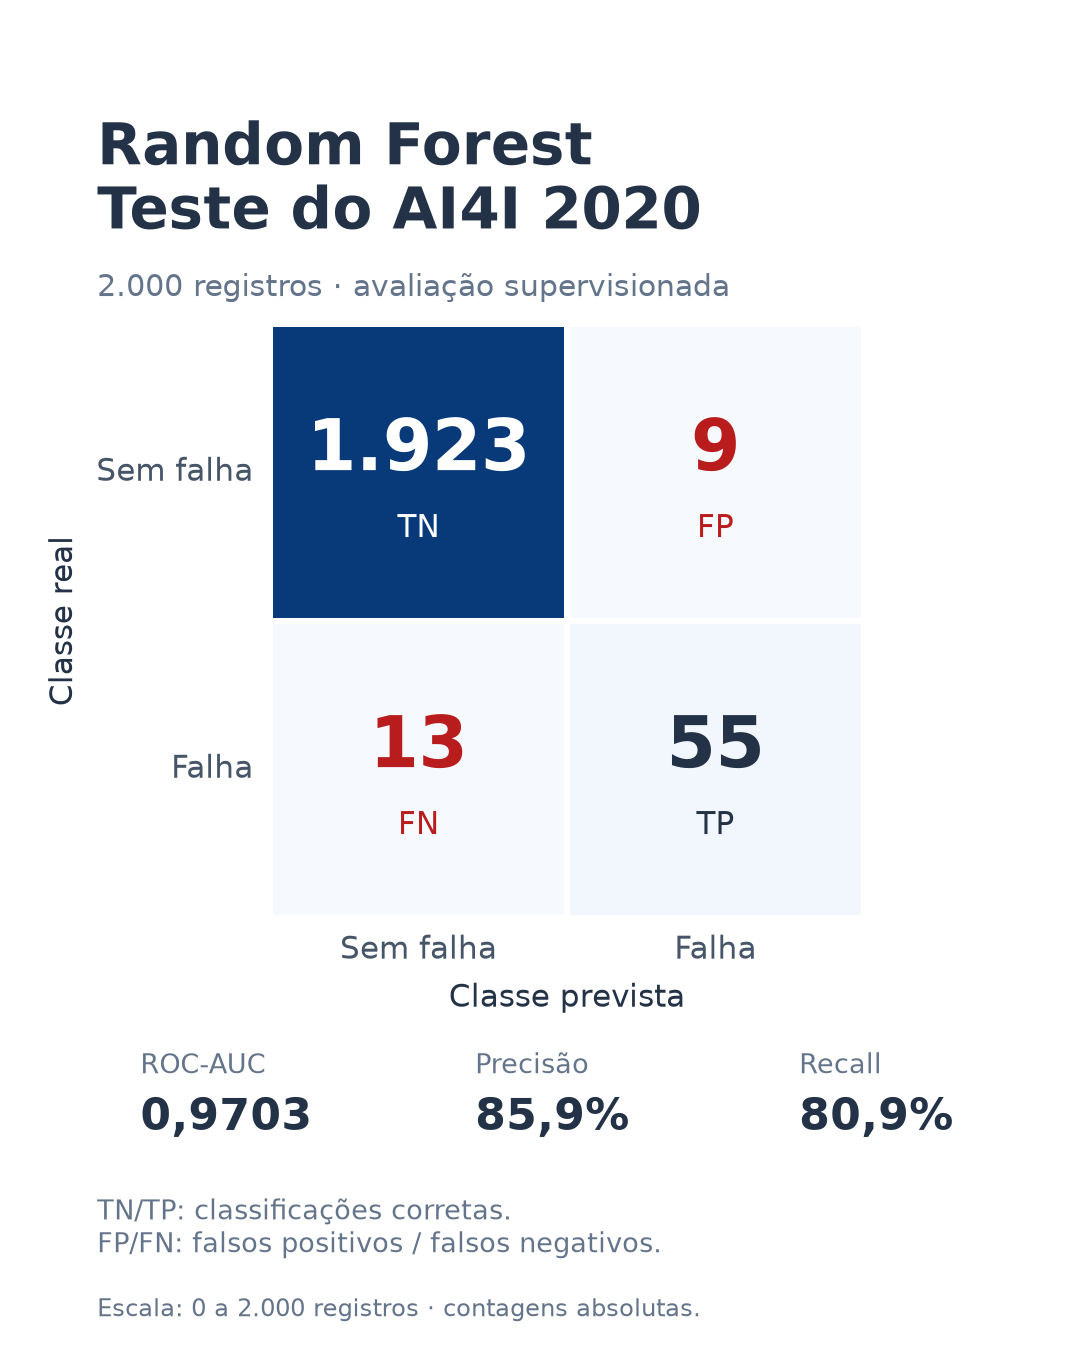

Figura conferida e preservada: confusion_matrix.png


In [10]:
fig = analysis_figure("Random Forest\nTeste do AI4I 2020", f"{format_br(len(testing))} registros · avaliação supervisionada")
ax = fig.add_axes([0.25, 0.32, 0.55, 0.44])
sns.heatmap(cm, annot=False, cmap="Blues", vmin=0, vmax=int(cm.sum()),
            linewidths=1.4, linecolor="white", cbar=False, ax=ax,
            xticklabels=["Sem falha", "Falha"], yticklabels=["Sem falha", "Falha"])
for row in range(2):
    for column in range(2):
        value = cm[row, column]
        light_text = value > cm.sum() * 0.5
        color = "white" if light_text else (RED if row != column else INK)
        ax.text(column + 0.5, row + 0.43, format_br(value), ha="center", va="center",
                fontsize=17, fontweight="bold", color=color)
        ax.text(column + 0.5, row + 0.69, [["TN", "FP"], ["FN", "TP"]][row][column],
                ha="center", va="center", fontsize=7.5, color=color)
ax.set(xlabel="Classe prevista", ylabel="Classe real")
ax.tick_params(axis="both", labelsize=7.4, length=0, pad=4)
ax.tick_params(axis="y", rotation=0)
ax.xaxis.label.set_size(7.5)
ax.yaxis.label.set_size(7.5)
metric_items = [("ROC-AUC", format_br(metrics["ROC-AUC"], 4)),
                ("Precisão", f"{format_br(metrics['Precisão da classe falha'] * 100, 1)}%"),
                ("Recall", f"{format_br(metrics['Recall da classe falha'] * 100, 1)}%")]
for position, (label, value) in zip([0.13, 0.44, 0.74], metric_items):
    fig.text(position, 0.205, label, fontsize=6.5, color=GRAY)
    fig.text(position, 0.163, value, fontsize=10.5, fontweight="bold", color=INK)
fig.text(0.09, 0.115, "TN/TP: classificações corretas.\nFP/FN: falsos positivos / falsos negativos.",
         fontsize=6.4, color=GRAY, va="top", linespacing=1.25)
fig.text(0.09, 0.025, f"Escala: 0 a {format_br(cm.sum())} registros · contagens absolutas.",
         fontsize=5.8, color=GRAY)
save_figure(fig, "confusion_matrix.png")

## 8. Figura 4 · Distribuições dos cinco sensores

Os boxplots do Seaborn comparam RPM, temperatura do processo, temperatura ambiente, torque e desgaste: **8.000 registros de treinamento, 58 amostras normais e 60 perturbadas**. Cada painel preserva a unidade e a escala do sensor. As caixas mostram a mediana e os 50% centrais; os bigodes alcançam os valores observados mais extremos dentro de [Q1 − 1,5 × AIQ; Q3 + 1,5 × AIQ], com AIQ = Q3 − Q1. Portanto, 1,5 × AIQ define as cercas estatísticas, não o comprimento fixo dos bigodes.

A temperatura do cenário perturbado se estende além dos valores do treinamento. Ambiente constante e desgaste restrito a 0–100 min evidenciam a diversidade limitada das simulações. Pontos fora dos bigodes **não são anomalias previstas pelo IF**. Como a amostragem temporal é irregular, os boxplots descrevem registros, não o tempo de exposição a cada condição.

Figura gerada e verificada: sensor_distributions.png


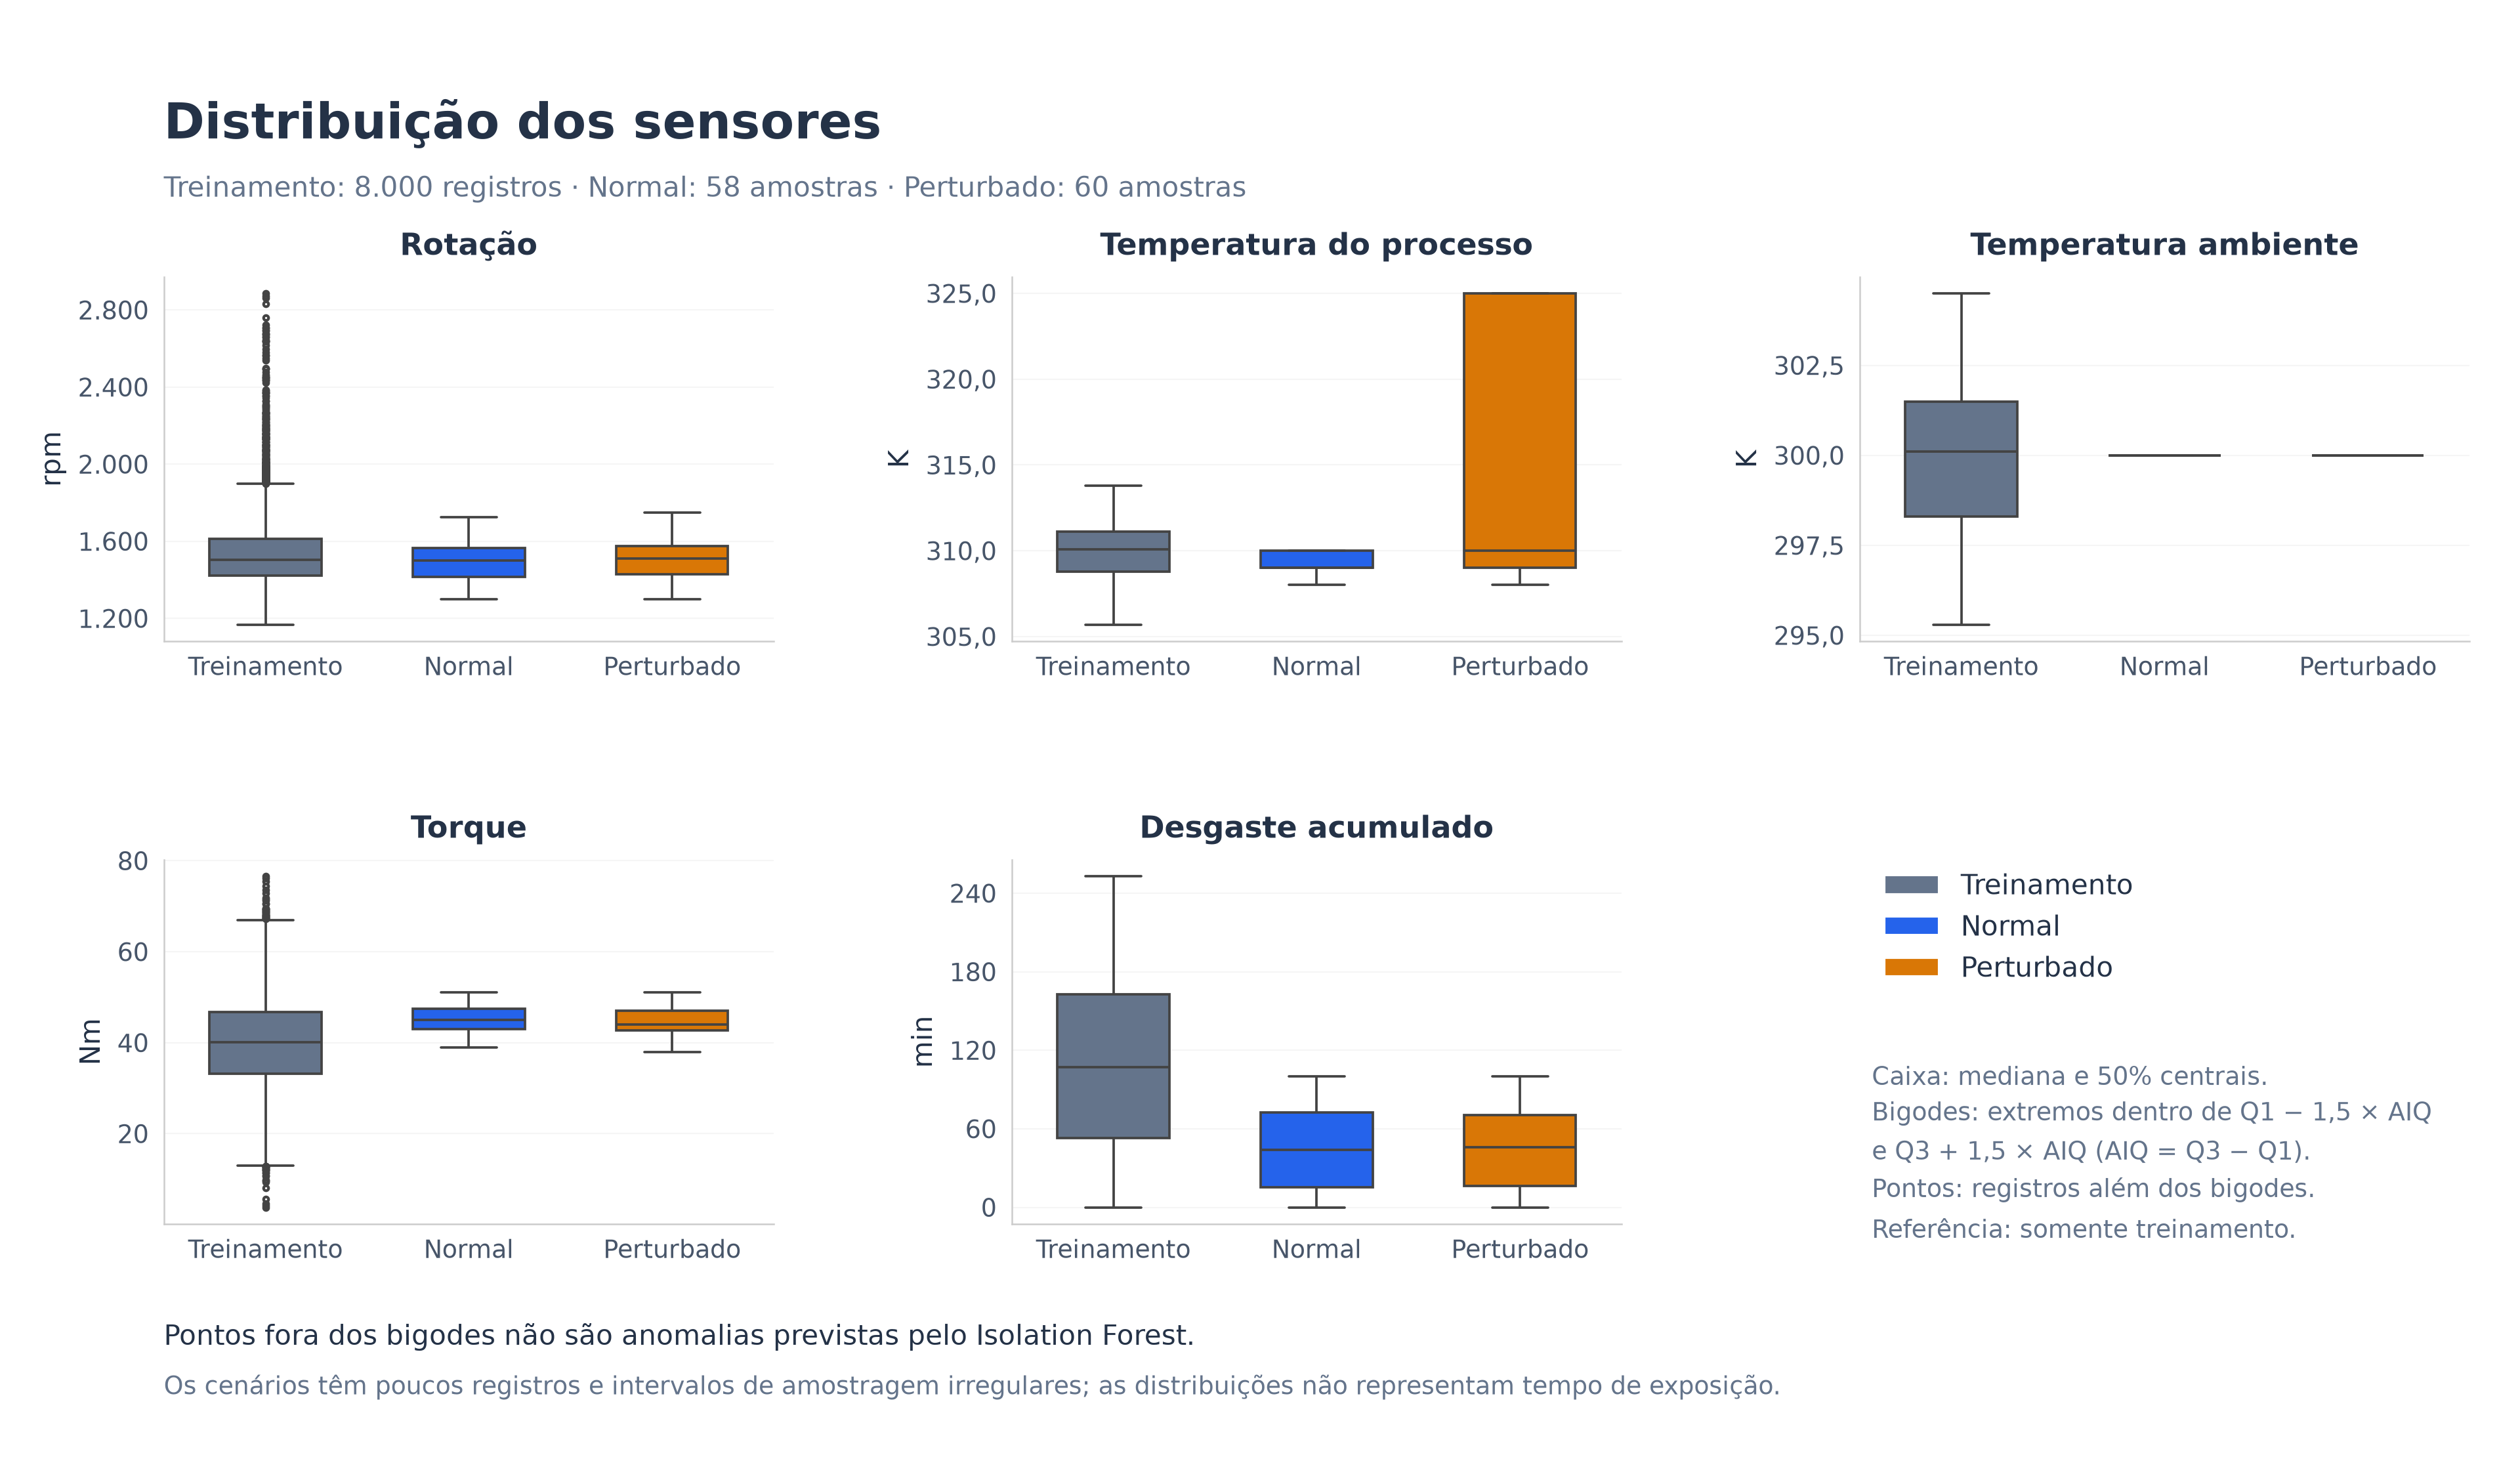

In [11]:
sensor_labels = {
    "rotational_speed_rpm": ("Rotação", "rpm"),
    "process_temperature_k": ("Temperatura do processo", "K"),
    "air_temperature_k": ("Temperatura ambiente", "K"),
    "torque_nm": ("Torque", "Nm"),
    "tool_wear_min": ("Desgaste acumulado", "min"),
}
distribution_frames = [training[SENSOR_COLUMNS].assign(cenario="Treinamento")]
distribution_frames.extend(frame[SENSOR_COLUMNS].assign(cenario=name) for name, frame in runs.items())
distributions = pd.concat(distribution_frames, ignore_index=True)
order = ["Treinamento", "Normal", "Perturbado"]
fig, axes = plt.subplots(2, 3, figsize=(12.8, 7.4))
fig.subplots_adjust(left=0.065, right=0.98, top=0.81, bottom=0.16, hspace=0.60, wspace=0.39)
fig.text(0.065, 0.905, "Distribuição dos sensores", fontsize=18, fontweight="bold")
fig.text(0.065, 0.865, f"Treinamento: {format_br(len(training))} registros · Normal: {format_br(len(runs['Normal']))} amostras · Perturbado: {format_br(len(runs['Perturbado']))} amostras",
         fontsize=10, color=GRAY)
for ax, (sensor, (title, unit)) in zip(axes.flat, sensor_labels.items()):
    sns.boxplot(data=distributions, x="cenario", y=sensor, hue="cenario", order=order,
                hue_order=order, palette=COLORS, saturation=1, legend=False,
                width=0.55, fliersize=1.8, linewidth=0.9, ax=ax)
    ax.set(title=title, xlabel="", ylabel=unit)
    ax.set_title(title, fontsize=11, pad=8)
    ax.tick_params(axis="both", labelsize=9, length=2)
    ax.yaxis.label.set_size(10)
    decimals = 1 if sensor in ["process_temperature_k", "air_temperature_k"] else 0
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, position, digits=decimals: format_br(value, digits)))
    ax.yaxis.set_major_locator(MaxNLocator(5))
    ax.grid(axis="x", visible=False)
axes.flat[-1].axis("off")
axes.flat[-1].legend(handles=[Patch(facecolor=COLORS[name], label=name) for name in order],
                     loc="upper left", bbox_to_anchor=(0, 1.03), frameon=False, fontsize=10)
axes.flat[-1].text(0.02, 0.46, "Caixa: mediana e 50% centrais.\nBigodes: extremos dentro de Q1 − 1,5 × AIQ\ne Q3 + 1,5 × AIQ (AIQ = Q3 − Q1).\nPontos: registros além dos bigodes.\nReferência: somente treinamento.",
                   transform=axes.flat[-1].transAxes, va="top", fontsize=9, color=GRAY, linespacing=1.55)
fig.text(0.065, 0.077, "Pontos fora dos bigodes não são anomalias previstas pelo Isolation Forest.", fontsize=10, color=INK)
fig.text(0.065, 0.043, "Os cenários têm poucos registros e intervalos de amostragem irregulares; as distribuições não representam tempo de exposição.",
         fontsize=9, color=GRAY)
save_figure(fig, "sensor_distributions.png")

## 9. Síntese e limites da interpretação

A síntese é calculada a partir das previsões atuais. Na referência validada, o RF teve ROC-AUC de 0,9703 no teste AI4I. Na telemetria, cada cenário apresentou nove classificações iniciais RF e nenhuma anomalia IF; a perturbação gerou 27 avisos de temperatura fora da faixa, sem novas classificações de falha RF nem anomalias IF após 50 s.

O treinamento ajusta os modelos usando dados e rótulos; aqui ocorre apenas inferência com artefatos já persistidos. Os modelos avaliam cada amostra e não recebem tempo nem derivada da temperatura. Não é calculada acurácia da telemetria, pois faltam rótulos físicos independentes. Um aviso de faixa informa extrapolação, não confirma falha ou anomalia.

In [12]:
normal = runs["Normal"]
post = perturbed[perturbed.time_s >= 50]
startup = perturbed[perturbed.failure_predicted.astype(bool)]
startup_text = (f"{len(startup)} registros sinalizados pelo RF, entre {startup.time_s.min():.3f} e {startup.time_s.max():.3f} s"
                if len(startup) else "nenhum registro sinalizado pelo RF")
display(Markdown(
    f"**Resultados desta execução:** o cenário normal contém {len(normal)} amostras, "
    f"{int(normal.failure_predicted.sum())} classificações RF e {int(normal.is_anomaly.sum())} anomalias IF. "
    f"O cenário perturbado contém {len(perturbed)} amostras. O salto observado foi de **{observed_jump:g} K**. "
    f"A partir de 50 s houve **{int(post.failure_predicted.sum())} classificações RF** e "
    f"**{int(post.is_anomaly.sum())} anomalias IF**, com {int(post.outside_training.sum())} registros "
    f"contendo sensor fora da faixa do treinamento. No cenário perturbado: {startup_text}. "
    "Contagens de registros não representam eventos físicos independentes."
))

**Resultados desta execução:** o cenário normal contém 58 amostras, 9 classificações RF e 0 anomalias IF. O cenário perturbado contém 60 amostras. O salto observado foi de **15 K**. A partir de 50 s houve **0 classificações RF** e **0 anomalias IF**, com 27 registros contendo sensor fora da faixa do treinamento. No cenário perturbado: 9 registros sinalizados pelo RF, entre 0.000 e 2.604 s. Contagens de registros não representam eventos físicos independentes.

## 10. Verificação e gravação das figuras

As quatro imagens são geradas em uma pasta temporária. A etapa final verifica os PNG, a resolução de 300 DPI, as dimensões de 1080 × 1350 px das três figuras verticais e a integridade dos arquivos de código, dados e modelos. Após essas verificações, substitui as figuras em `reports/figures/`.

A limpeza se restringe às variantes de mesmo nome-base com sufixos `_old`, `_backup` ou `_v` seguido de número. Outros arquivos são preservados e a pasta temporária é descartada ao final.

In [13]:
exports = []
for filename in EXPECTED_FIGURES:
    path = STAGING / filename
    assert path.is_file() and path.stat().st_size > 0
    with PILImage.open(path) as image:
        image.verify()
    with PILImage.open(path) as image:
        dpi = image.info.get("dpi", (0, 0))
        assert min(dpi) >= 299.9
        if filename in VERTICAL_FIGURES:
            assert image.size == (1080, 1350)
        exports.append({"Arquivo": str((FIGURES / filename).relative_to(ROOT)),
                        "Largura (px)": image.width, "Altura (px)": image.height,
                        "DPI": round(min(dpi))})
changed = [str(path.relative_to(ROOT)) for path, before in original_hashes.items()
           if not path.exists() or sha256(path) != before]
assert not changed, f"Arquivos protegidos alterados: {changed}"
for filename in EXPECTED_FIGURES:
    os.replace(STAGING / filename, FIGURES / filename)
removed = []
for filename in EXPECTED_FIGURES:
    stem = Path(filename).stem
    variant = re.compile(rf"{re.escape(stem)}_(?:old|backup|v[0-9]+)\.png", re.IGNORECASE)
    for candidate in FIGURES.iterdir():
        if candidate.is_file() and variant.fullmatch(candidate.name):
            candidate.unlink()
            removed.append(candidate.name)
staging_context.cleanup()
display(pd.DataFrame(exports))
print("Quatro figuras verificadas e salvas em reports/figures/.")
print(f"Variantes antigas removidas: {', '.join(removed) if removed else 'nenhuma encontrada'}.")
print(f"Integridade confirmada: {len(original_hashes)} arquivos protegidos permaneceram intactos.")

Revisão numérica: matriz, métricas, 58/60 amostras, RF 9/9, IF 0/0, salto de 15 K e 27 avisos independentes confirmados.


,Arquivo,Largura (px),Altura (px),DPI
0,reports/figures/temperature_comparison.png,1080,1350,300
1,reports/figures/confusion_matrix.png,1080,1350,300
2,reports/figures/model_predictions.png,1080,1350,300
3,reports/figures/sensor_distributions.png,3840,2220,300


Quatro figuras verificadas e salvas em reports/figures/.
Variantes antigas removidas: nenhuma encontrada.
Integridade confirmada: 29 arquivos protegidos permaneceram intactos.


### Como repetir a análise

1. Abra este notebook no VS Code ou Jupyter e selecione o ambiente `.venv` do projeto.
2. Execute as células em sequência, incluindo a verificação final que grava as quatro figuras.
3. Confira os hashes dos modelos, a matriz recalculada e as contagens dos dois cenários.
4. Consulte os PNG em `reports/figures/` e as tabelas para interpretar os resultados.

As saídas incorporadas permitem consultar a análise sem executá-la novamente. Os dados originais e os modelos são somente lidos; apenas as figuras são substituídas. Para avaliar uma nova execução, verifique sempre a versão dos artefatos e as limitações descritas nas seções anteriores.